# Spam Message Detection

We will load the spam dataset and inspect its size, columns, and first few rows.

In [5]:
import pandas as pd

sms_df = pd.read_csv(
    "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "text"]
)

print("Dataset shape:", sms_df.shape)
print("\nLabel counts:")
print(sms_df["label"].value_counts())
sms_df.head()

Dataset shape: (5572, 2)

Label counts:
label
ham     4825
spam     747
Name: count, dtype: int64


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## Check the Dataset

We will confirm the column types and check for missing values before cleaning the messages.


In [6]:
sms_df.info()

print("\nMissing values:")
print(sms_df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   label   5572 non-null   str  
 1   text    5572 non-null   str  
dtypes: str(2)
memory usage: 542.9 KB

Missing values:
label    0
text     0
dtype: int64


The dataset check succeeded: it has 5,572 messages, two text columns, and no missing values.

## Check for Empty and Repeated Messages

We will count blank messages, duplicate rows, and repeated messages before deciding what to remove.

In [7]:
print("Empty messages:", sms_df["text"].str.strip().eq("").sum())
print("Duplicate rows:", sms_df.duplicated().sum())
print("Repeated messages:", sms_df["text"].duplicated().sum())
print(
    "Repeated messages with different labels:",
    (sms_df.groupby("text")["label"].nunique() > 1).sum()
)

Empty messages: 0
Duplicate rows: 403
Repeated messages: 403
Repeated messages with different labels: 0


## Remove Duplicate Messages

We will keep one copy of each message and its label.

In [8]:
sms_df = sms_df.drop_duplicates(subset="text", keep="first").reset_index(drop=True)

print("Cleaned dataset shape:", sms_df.shape)
print("\nLabel counts:")
print(sms_df["label"].value_counts())

Cleaned dataset shape: (5169, 2)

Label counts:
label
ham     4516
spam     653
Name: count, dtype: int64


## Create Spam Labels

We will encode spam messages as 1 and ham messages as 0 so the model can learn to classify them.

In [9]:
sms_df["spam_label"] = (sms_df["label"] == "spam").astype(int)

print("Ham (0) and spam (1) counts:")
print(sms_df["spam_label"].value_counts().sort_index())

Ham (0) and spam (1) counts:
spam_label
0    4516
1     653
Name: count, dtype: int64


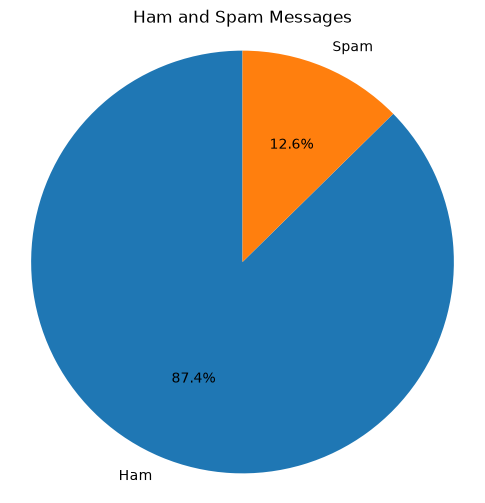

In [10]:
import matplotlib.pyplot as plt

label_counts = sms_df["label"].value_counts().reindex(["ham", "spam"])

plt.figure(figsize=(6, 6))
plt.pie(
    label_counts,
    labels=["Ham", "Spam"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Ham and Spam Messages")
plt.axis("equal")
plt.show()

## Split the Data

We will create training, validation, and test sets. Stratifying keeps the ham and spam proportions similar in each set.

In [11]:
from sklearn.model_selection import train_test_split

sms_train, sms_remaining = train_test_split(
    sms_df,
    test_size=0.30,
    random_state=42,
    stratify=sms_df["spam_label"]
)

sms_validation, sms_test = train_test_split(
    sms_remaining,
    test_size=0.50,
    random_state=42,
    stratify=sms_remaining["spam_label"]
)

print("Training rows:", len(sms_train))
print("Validation rows:", len(sms_validation))
print("Test rows:", len(sms_test))

Training rows: 3618
Validation rows: 775
Test rows: 776


## Prepare the SMS Text

We will tokenize, remove less useful stop words, and lemmatize the messages. We will keep negation, numbers, and words such as “you,” “your,” and “now,” which can help identify spam.

In [12]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")

spam_stop_words = set(stopwords.words("english")) - {
    "no", "nor", "not", "n't", "you", "your", "now", "to"
}
spam_lemmatizer = WordNetLemmatizer()

def prepare_sms_text(message):
    tokens = word_tokenize(str(message).lower())

    tokens = [
        spam_lemmatizer.lemmatize(token)
        for token in tokens
        if (token.isalnum() or token == "n't")
        and token not in spam_stop_words
    ]

    return " ".join(tokens)

sms_train["processed_text"] = sms_train["text"].apply(prepare_sms_text)
sms_validation["processed_text"] = sms_validation["text"].apply(prepare_sms_text)
sms_test["processed_text"] = sms_test["text"].apply(prepare_sms_text)

print(sms_train["processed_text"].head())


[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Nandini\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Nandini\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Nandini\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


1679                         think going to finn now come
31      yeah got 2 v apologetic n fallen actin like sp...
3880    hi baby ive got back work wanting to see u all...
1196                               jus an lar u noe later
446     ok tell to stay yeah tough optimistic thing im...
Name: processed_text, dtype: str


## Convert SMS Text to TF-IDF Features

We will represent the messages as numbers using TF-IDF with single words and two-word phrases. The vectorizer will learn from training messages only.

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

sms_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=20000
)

sms_train_features = sms_vectorizer.fit_transform(sms_train["processed_text"])
sms_validation_features = sms_vectorizer.transform(sms_validation["processed_text"])
sms_test_features = sms_vectorizer.transform(sms_test["processed_text"])

print("Training feature shape:", sms_train_features.shape)
print("Validation feature shape:", sms_validation_features.shape)
print("Test feature shape:", sms_test_features.shape)

Training feature shape: (3618, 5709)
Validation feature shape: (775, 5709)
Test feature shape: (776, 5709)


## Train the Spam Classifier

We’ll train a Multinomial Naive Bayes model on the training messages. It works with nonnegative TF-IDF features and is a good fit for text classification.

In [14]:
from sklearn.naive_bayes import MultinomialNB

spam_model = MultinomialNB()
spam_model.fit(sms_train_features, sms_train["spam_label"])

print("Spam model training complete.")

Spam model training complete.


## Choose the Spam Cutoff, with this text:

We will choose the probability cutoff that gives the best F1 score on the validation messages. The test set remains reserved for the final evaluation.

In [15]:
import numpy as np
from sklearn.metrics import precision_recall_curve

spam_probabilities = spam_model.predict_proba(sms_validation_features)[
    :, list(spam_model.classes_).index(1)
]

precision, recall, thresholds = precision_recall_curve(
    sms_validation["spam_label"],
    spam_probabilities
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)
spam_threshold = thresholds[best_index]

print("Chosen spam cutoff:", round(spam_threshold, 3))
print("Validation F1-score:", round(f1_scores[best_index], 3))

Chosen spam cutoff: 0.148
Validation F1-score: 0.868


## Evaluate on the Test Data

We will apply the cutoff chosen on the validation set to the test messages and report precision, recall, F1 score, and the number of actual spam messages.

In [17]:
from sklearn.metrics import precision_recall_fscore_support

test_spam_probabilities = spam_model.predict_proba(sms_test_features)[
    :, list(spam_model.classes_).index(1)
]

test_spam_predictions = (test_spam_probabilities >= spam_threshold).astype(int)

precision, recall, f1, support = precision_recall_fscore_support(
    sms_test["spam_label"],
    test_spam_predictions,
    average="binary",
    zero_division=0
)

spam_results = pd.DataFrame(
    [{
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Actual spam messages": int(sms_test["spam_label"].sum())
    }],
    index=["Spam"]
).round(3)

spam_results

,Precision,Recall,F1-score,Actual spam messages
Spam,0.861,0.888,0.874,98


## Save the Spam Model

We will save the trained spam classifier, TF-IDF vectorizer, and validation-selected cutoff together so they can be reused.

In [18]:
import joblib

spam_bundle = {
    "model": spam_model,
    "vectorizer": sms_vectorizer,
    "threshold": spam_threshold,
    "label_mapping": {"ham": 0, "spam": 1}
}

joblib.dump(spam_bundle, "spam_model.joblib")
print("Spam model saved.")

Spam model saved.
